<a href="https://colab.research.google.com/github/TejasShrestha/DATA201-labs/blob/main/Assignments/Week8_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Tejas' Week 8 Homework**

### **Loading the ISLP Hitters dataset and doing necessary cleaning**

In [2]:
%pip -q install ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

In [4]:
hitters = load_data('Hitters')
print('Original shape:', hitters.shape)
display(hitters.head())
print('Missing values:')
print(hitters.isna().sum().sort_values())

Original shape: (322, 20)


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N


Missing values:
AtBat         0
Hits          0
HmRun         0
Runs          0
RBI           0
Walks         0
Years         0
CAtBat        0
CHits         0
CHmRun        0
CRuns         0
CRBI          0
CWalks        0
League        0
Division      0
PutOuts       0
Assists       0
Errors        0
NewLeague     0
Salary       59
dtype: int64


In [5]:
#remove the missing information
hitters = hitters.dropna(subset=['Salary']).copy()

#Set your features and target
X = hitters.drop(columns='Salary')
y = hitters['Salary']    # thousands of dollars

#define num/cat for later scaling and encoding
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
category_cols = X.select_dtypes(exclude=np.number).columns.tolist()
print(category_cols)

#split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

#you can check how many rows went for each set
print(len(X), len(X_train), len(X_test))

['League', 'Division', 'NewLeague']
263 197 66


In [6]:
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), category_cols)
            ])

baseline = Pipeline([
    ('preprocess', make_preprocessor()),
    ('model', LinearRegression())
])

baseline.fit(X_train, y_train)

def measure(name, fitted_model):
    train_pred = fitted_model.predict(X_train)
    test_pred = fitted_model.predict(X_test)
    return {
        'Model': name,
        'Train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
        'Test R²': r2_score(y_test, test_pred)
    }

results = [measure('Linear regression (no penalty)', baseline)]
display(pd.DataFrame(results).round(2))

,Model,Train RMSE,Test RMSE,Test R²
0,Linear regression (no penalty),289.33,357.05,0.41


## **Part 1 - Experiment with alpha**

In [7]:
alpha_values = [0.1, 10, 100]
rows = []
for kind, estimator in [('Lasso', Lasso(max_iter=30000))]:

    for a in alpha_values:
        pipe = Pipeline([
            ('preprocess', make_preprocessor()),
            ('model', estimator.set_params(alpha=a))
        ])
        pipe.fit(X_train, y_train)

        #get the model's coefficients
        coefs = pipe.named_steps['model'].coef_

        #each time the loop runs, we add one dictionary to the list "rows".
        rows.append({
            'Model': kind, 'alpha': a,
            'Nonzero coefficients': int(np.sum(np.abs(coefs) > 1e-6)), #count nonzero coefficients
            'Training RMSE': np.sqrt(mean_squared_error(y_train, pipe.predict(X_train))),
            'Test RMSE': np.sqrt(mean_squared_error(y_test, pipe.predict(X_test)))
        })
alpha_table = pd.DataFrame(rows)
display(alpha_table.round(2))

,Model,alpha,Nonzero coefficients,Training RMSE,Test RMSE
0,Lasso,0.1,19,289.38,356.83
1,Lasso,10.0,9,303.10,381.84
2,Lasso,100.0,5,341.39,395.12


### **Questions:**

**1. As α increases, what happens to the number of retained predictors?**

As alpha increases, the number of nonzero coefficients decreases, Training RMSE increases, and Test RMSE increases.

**2. Does a smaller number of predictors always lead to a lower test RMSE?**

A smaller number of predictors does not always lead to a lower test RMSE.

## **Part 2 - Visualize and interpret**

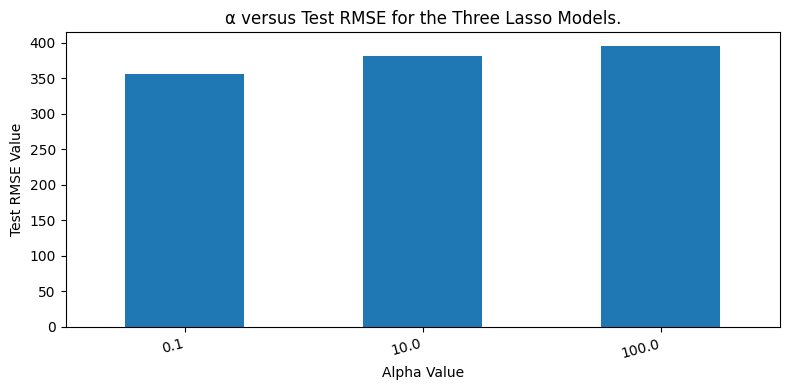

In [8]:
ax = alpha_table.plot(kind='bar', x='alpha', y='Test RMSE', legend=False, figsize=(8, 4))
ax.set_ylabel('Test RMSE Value')
ax.set_xlabel('Alpha Value')
ax.set_title('α versus Test RMSE for the Three Lasso Models.')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

### **Questions:**

**1. Which α produces the lowest test RMSE among the three values?**

The alpha that produces the lowest test RMSE among the three values is 0.1

**2. Which α appears to cause the most underfitting? Explain using bias.**

The alpha that appears to cause the most undefitting is 100. Since the RMSE value is the highest for this alpha, it increases bias, restricting the model's ability to collect data.

**3. Why might a model with higher training RMSE produce lower test RMSE?**

A model with higher training RMSE may produce lower test RMSE because the model will have already learned too much of the data in the training side making the test side already familiar with the data.

## **Part 3 - Model Interpretation**

In [16]:
feature_names = baseline.named_steps['preprocess'].get_feature_names_out()

lasso_alpha_100 = Pipeline([
    ('preprocess', make_preprocessor()),
    ('model', Lasso(alpha=100, max_iter=30000))
])
lasso_alpha_100.fit(X_train, y_train)

coef_table = pd.DataFrame({
    'Feature': feature_names,
    'OLS': baseline.named_steps['model'].coef_,
    'Lasso': lasso_alpha_100.named_steps['model'].coef_
})

display(coef_table.round(2))

,Feature,OLS,Lasso
0,num__AtBat,-252.65,0.00
1,num__Hits,379.23,76.59
2,num__HmRun,64.67,0.00
3,num__Runs,-82.33,0.00
4,num__RBI,-52.67,0.00
5,num__Walks,113.43,16.17
6,num__Years,35.91,0.00
7,num__CAtBat,-318.63,0.00
8,num__CHits,-136.22,0.00
9,num__CHmRun,-50.89,0.00


**1. Identify two predictors that Lasso sets to zero at α = 100.**

num_HmrRun and num_AtBat

**2. Does setting their coefficients to zero prove that these predictors have no relationship with salary? Explain.**

Setting their coefficients to zero does not prove that these predictors have no relationship with salary. Lasso only sets these coefficeints to zero due to them not being a significant factor. This could be because the information is already learned in another feature.

**3. If two models have very similar test RMSE but one uses fewer predictors, which would you prefer? Explain your answer in terms of interpretability and predictive performance.**

I would choose the one that uses fewer predictors because it would be more simple to understand. This will also help reduce our CPU usage too while having the same effectivesness with both models predicting very similarly.

## **Part 4 - Choosing the Right Regression Model**

### **- Scenario A: A researcher has data from 80 patients with 200 medical measurements. The goal is to identify a small number of measurements that may be useful for predicting disease severity.**

  Lasso. Since the goal is for the researcher to identify a small number of measurements, lasso can remove the features that are not as useful. This will make it easier to figure out which ones we need in this scenario.

### **- Scenario B: A company wants to predict employee salaries using 40 predictors. Many predictors are strongly correlated, and the company believes most contain useful information. Keeping all predictors is not a concern.**

  Ridge. Since many predictors are strongly correlated, ridge would be the best choice because it keeps all the features and does not remove any.

### **- Scenario C: A researcher has 10,000 observations and only three predictors. The relationship appears approximately linear, and the researcher wants a simple model that is easy to interpret.**

  Ordinary Linear Regression. Since the relationship is appreaing to be linear and the researcher wants a simple model, ordinary linear regression model meets this qualities. It is simple and works with linear relationships.

### **- Scenario D: A company has 500 observations and 25 predictors. It is unclear how many predictors are useful or how strongly they are correlated. The company wants the most accurate predictions possible.**

  Not Sure. Since the scenari states that it is unclear to know how many predictors are useful or strongly correlated, this makes it hard to choose. We don't know the relatonship and if many features are important or just a few. We would need more information to make a decision.